In [5]:
%load_ext autoreload
%autoreload 2

import os
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from dotenv import load_dotenv
from google.cloud import bigquery

# find the project root (the folder containing pyproject.toml)
ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
RAW = ROOT / "data" / "raw"

load_dotenv(ROOT / ".env")
client = bigquery.Client(project=os.getenv("GCP_PROJECT_ID"))

DATASET = "bigquery-public-data.google_political_ads"
START, END = "2026-01-01", "2026-11-15"
print("Project root:", ROOT)
print("GCP project:", client.project)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Project root: /home/rushi/projects/midterm-ad-topic
GCP project: midterm-ads-rushi


In [6]:
schema = client.query(f"""
SELECT table_name, column_name, data_type
FROM `{DATASET}.INFORMATION_SCHEMA.COLUMNS`
WHERE table_name IN ('creative_stats', 'advertiser_weekly_spend')
ORDER BY table_name, ordinal_position
""").to_dataframe()

schema

/home/rushi/projects/midterm-ad-topic/.venv/lib/python3.12/site-packages/google/cloud/bigquery/table.py:2131: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


,table_name,column_name,data_type
0,advertiser_weekly_spend,advertiser_id,STRING
1,advertiser_weekly_spend,advertiser_name,STRING
2,advertiser_weekly_spend,election_cycle,STRING
3,advertiser_weekly_spend,week_start_date,DATE
4,advertiser_weekly_spend,spend_usd,INT64
...,...,...,...
78,creative_stats,spend_range_max_zar,INT64
79,creative_stats,spend_range_min_clp,INT64
80,creative_stats,spend_range_max_clp,INT64
81,creative_stats,spend_range_min_mxn,INT64


In [7]:
def estimate_gb(sql: str) -> float:
    """Return how many GB a query would scan, without running it."""
    cfg = bigquery.QueryJobConfig(dry_run=True, use_query_cache=False)
    return client.query(sql, job_config=cfg).total_bytes_processed / 1e9

ads_sql = f"""
SELECT ad_id, ad_url, ad_type, advertiser_id, advertiser_name,
       date_range_start, date_range_end, num_of_days,
       impressions, spend_range_min_usd, spend_range_max_usd,
       geo_targeting_included
FROM `{DATASET}.creative_stats`
WHERE regions LIKE '%US%'
  AND date_range_end   >= DATE '{START}'
  AND date_range_start <= DATE '{END}'
"""

print(f"Ads query would scan {estimate_gb(ads_sql):.2f} GB")

Ads query would scan 2.25 GB


In [8]:
ads = client.query(ads_sql).to_dataframe()
ads.to_parquet(RAW / "google_ads_2026.parquet", index=False)
print(ads.shape)
ads.head()

/home/rushi/projects/midterm-ad-topic/.venv/lib/python3.12/site-packages/google/cloud/bigquery/table.py:2131: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


(159377, 12)


,ad_id,ad_url,ad_type,advertiser_id,advertiser_name,date_range_start,date_range_end,num_of_days,impressions,spend_range_min_usd,spend_range_max_usd,geo_targeting_included
0,CR17514729169680859137,https://adstransparency.google.com/advertiser/...,VIDEO,AR00001261835621761025,No Gerrymandering Virginia (NGV),2026-04-16,2026-04-21,6,1750000-2000000,15000,20000,"Virginia,United States"
1,CR01277559436902137857,https://adstransparency.google.com/advertiser/...,VIDEO,AR00005094630076973057,City Action Michigan,2026-10-15,2026-11-04,20,2500000-3000000,50000,60000,"MI-4 (2022 redistricting),Michigan,United States"
2,CR12517981156865474561,https://adstransparency.google.com/advertiser/...,VIDEO,AR00005094630076973057,City Action Michigan,2026-10-15,2026-11-04,20,2500000-3000000,50000,60000,"MI-7 (2022 redistricting),Michigan,United States"
3,CR15243945188230430721,https://adstransparency.google.com/advertiser/...,VIDEO,AR00005353943022436353,Bill Cassidy for US Senate & LA Victory,2026-04-23,2026-04-25,3,900000-1000000,15000,20000,United States
4,CR04159237954260172801,https://adstransparency.google.com/advertiser/...,VIDEO,AR00005353943022436353,Bill Cassidy for US Senate & LA Victory,2026-04-25,2026-05-02,7,1250000-1500000,15000,20000,United States


In [9]:
weekly_sql = f"""
SELECT advertiser_id, advertiser_name, week_start_date, spend_usd
FROM `{DATASET}.advertiser_weekly_spend`
WHERE week_start_date BETWEEN DATE '{START}' AND DATE '{END}'
"""

print(f"Weekly query would scan {estimate_gb(weekly_sql):.2f} GB")
weekly = client.query(weekly_sql).to_dataframe()
weekly["week_start_date"] = pd.to_datetime(weekly["week_start_date"])
weekly.to_parquet(RAW / "google_weekly_spend_2026.parquet", index=False)
print(weekly.shape)
weekly.head()

Weekly query would scan 0.02 GB


/home/rushi/projects/midterm-ad-topic/.venv/lib/python3.12/site-packages/google/cloud/bigquery/table.py:2131: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


(69141, 4)


,advertiser_id,advertiser_name,week_start_date,spend_usd
0,AR00001261835621761025,No Gerrymandering Virginia (NGV),2026-04-12,9700
1,AR00001261835621761025,No Gerrymandering Virginia (NGV),2026-04-19,8800
2,AR00005094630076973057,City Action Michigan,2026-10-11,19800
3,AR00005094630076973057,City Action Michigan,2026-10-18,26800
4,AR00005094630076973057,City Action Michigan,2026-10-25,20500


In [10]:
print("Ads:", len(ads), "| Advertisers:", ads["advertiser_id"].nunique())
print("Date range:", ads["date_range_start"].min(), "to", ads["date_range_end"].max())
print()
print(ads["ad_type"].value_counts())
print()
print(ads["impressions"].value_counts())

Ads: 159377 | Advertisers: 6268
Date range: 2018-05-31 to 2026-11-20

ad_type
VIDEO    127760
IMAGE     16386
TEXT      15231
Name: count, dtype: int64

impressions
0-1000              28060
10000-15000          6639
1000-2000            6485
100000-125000        5414
15000-20000          5282
20000-25000          4462
125000-150000        4387
2000-3000            4333
50000-60000          4300
250000-300000        3924
60000-70000          3788
25000-30000          3678
150000-175000        3634
3000-4000            3621
30000-35000          3415
300000-350000        3214
175000-200000        3110
70000-80000          3034
35000-40000          3004
500000-600000        2998
4000-5000            2879
80000-90000          2862
40000-45000          2759
350000-400000        2669
200000-225000        2665
90000-100000         2551
5000-6000            2494
45000-50000          2425
600000-700000        2355
1000000-1250000      2308
225000-250000        2299
400000-450000        2265
600

In [11]:
# spend comes as a range; use the midpoint (if there is no max, fall back to the min)
ads["spend_mid_usd"] = (
    ads["spend_range_min_usd"] + ads["spend_range_max_usd"].fillna(ads["spend_range_min_usd"])
) / 2

top = (
    ads.groupby("advertiser_name")["spend_mid_usd"]
    .agg(total_spend="sum", n_ads="count")
    .sort_values("total_spend", ascending=False)
    .head(20)
)
top

,total_spend,n_ads
advertiser_name,,
Kalshi Inc,76674200.0,279
SLF PAC,34849450.0,3055
WINSENATE,33622100.0,1511
HMP,23060200.0,1035
JON OSSOFF FOR SENATE,21799750.0,261
MAGA INC.,20431700.0,4104
CLF,17123750.0,2400
Money Metals Exchange LLC,16973050.0,202
"NO ON PROP 40 - DOCTORS, TEACHERS, SMALL BUSINESSES, WORKING FAMILIES AND PUBLIC SAFETY AGAINST THE RECKLESS WEALTH TAX EXPERIMENT",16334100.0,1825


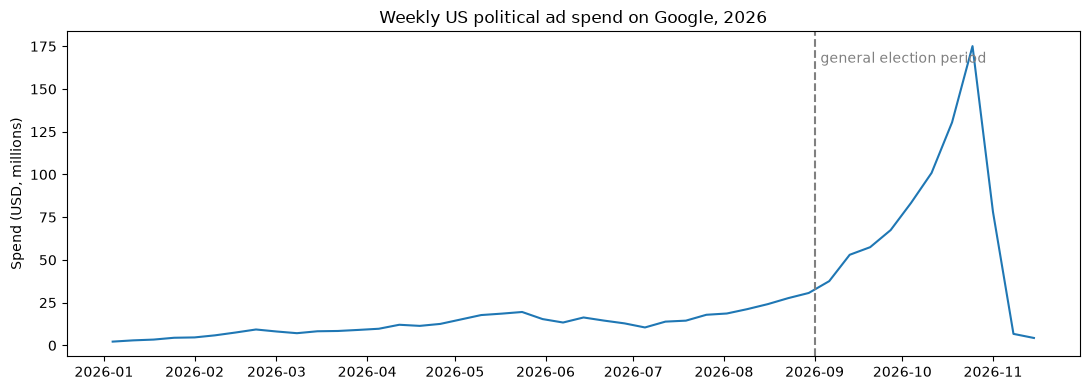

In [12]:
total_weekly = weekly.groupby("week_start_date")["spend_usd"].sum()

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(total_weekly.index, total_weekly.values / 1e6)
ax.axvline(pd.Timestamp("2026-09-01"), linestyle="--", color="grey")
ax.text(pd.Timestamp("2026-09-03"), ax.get_ylim()[1] * 0.9, "general election period", color="grey")
ax.set_title("Weekly US political ad spend on Google, 2026")
ax.set_ylabel("Spend (USD, millions)")
fig.tight_layout()
fig.savefig(ROOT / "reports" / "figures" / "google_weekly_spend_2026.png", dpi=150)
plt.show()

In [13]:
from datetime import date

ELECTION_DAY = pd.Timestamp("2026-11-03")
GENERAL_START = pd.Timestamp("2026-09-01")
END = date.today().isoformat()

weekly_sql = f"""
SELECT advertiser_id, advertiser_name, week_start_date, spend_usd
FROM `{DATASET}.advertiser_weekly_spend`
WHERE week_start_date BETWEEN DATE '{START}' AND DATE '{END}'
"""
print(f"Weekly query would scan {estimate_gb(weekly_sql):.2f} GB")

weekly = client.query(weekly_sql).to_dataframe()
weekly["week_start_date"] = pd.to_datetime(weekly["week_start_date"])
weekly.to_parquet(RAW / "google_weekly_spend_2026.parquet", index=False)
print(weekly.shape, "| latest week:", weekly["week_start_date"].max().date())

Weekly query would scan 0.02 GB


/home/rushi/projects/midterm-ad-topic/.venv/lib/python3.12/site-packages/google/cloud/bigquery/table.py:2131: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


(69141, 4) | latest week: 2026-11-15


In [14]:
client.query(f"""
SELECT MAX(week_start_date) AS latest_week
FROM `{DATASET}.advertiser_weekly_spend`
""").to_dataframe()

/home/rushi/projects/midterm-ad-topic/.venv/lib/python3.12/site-packages/google/cloud/bigquery/table.py:2131: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


,latest_week
0,2026-11-15


In [18]:
tables = client.query(f"""
SELECT table_name
FROM `{DATASET}.INFORMATION_SCHEMA.TABLES`
""").to_dataframe()

tables

/home/rushi/projects/midterm-ad-topic/.venv/lib/python3.12/site-packages/google/cloud/bigquery/table.py:2131: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


,table_name
0,geo_spend
1,advertiser_stats
2,advertiser_weekly_spend
3,advertiser_declared_stats
4,last_updated
5,advertiser_geo_spend
6,campaign_targeting
7,top_keywords_history
8,creative_stats


In [19]:
client.query(f"""
SELECT column_name, data_type
FROM `{DATASET}.INFORMATION_SCHEMA.COLUMNS`
WHERE table_name = 'advertiser_declared_stats'
""").to_dataframe()

/home/rushi/projects/midterm-ad-topic/.venv/lib/python3.12/site-packages/google/cloud/bigquery/table.py:2131: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


,column_name,data_type
0,advertiser_id,STRING
1,region,STRING
2,advertiser_declared_name,STRING
3,advertiser_declared_regulatory_id,STRING
4,advertiser_declared_scope,STRING
5,advertiser_declared_promoter_name,STRING
6,advertiser_declared_promoter_address,STRING


In [20]:
client.query(f"""
SELECT
  COUNT(*) AS advertisers,
  COUNTIF(advertiser_declared_regulatory_id IS NOT NULL
          AND advertiser_declared_regulatory_id != '') AS with_id
FROM `{DATASET}.advertiser_declared_stats`
""").to_dataframe()

/home/rushi/projects/midterm-ad-topic/.venv/lib/python3.12/site-packages/google/cloud/bigquery/table.py:2131: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


,advertisers,with_id
0,541,486


In [21]:
client.query(f"""
SELECT *
FROM `{DATASET}.advertiser_declared_stats`
WHERE advertiser_declared_regulatory_id IS NOT NULL
LIMIT 10
""").to_dataframe()

/home/rushi/projects/midterm-ad-topic/.venv/lib/python3.12/site-packages/google/cloud/bigquery/table.py:2131: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


,advertiser_id,region,advertiser_declared_name,advertiser_declared_regulatory_id,advertiser_declared_scope,advertiser_declared_promoter_name,advertiser_declared_promoter_address
0,AR11555370211490136065,CHE AHN FOR GOVERNOR 2026,US-CA,119580380,"California, Che Ahn for Governor 2026, Governor",NaN,NaN
1,AR15621574801842241537,California Environmental Voters Independent Ex...,US-CA,1236496,"CA Assemblymember, District 47, Christy Holstege",NaN,NaN
2,AR01707842411805278209,EQUALITY CALIFORNIA POLITICAL ACTION COMMITTEE,US-CA,1254010,"Assembly Member (AD20), Shawn Kumagai",NaN,NaN
3,AR00337697816602214401,"DaVita, Inc.",US-CA,1257183,"Angelique Ashby, California State Senate",NaN,NaN
4,AR15591194771580780545,Reform California with Carl DeMaio — Ballot Me...,US-CA,1268914,"California, Measure A, Measure B, Prop 3, Prop...",NaN,NaN
5,AR15958753666136014849,Reform California with Carl DeMaio - Ballot Me...,US-CA,1268914,"California, San Diego, Prop 36, Measure G, CA ...",NaN,NaN
6,AR12113864273780801537,"Working Californians, sponsored by Internation...",US-CA,1288733,"California candidate races, Gil Cedillo, LA Ci...",NaN,NaN
7,AR11621669757622681601,"Working Californians, Sponsored by Internation...",US-CA,1288733,"LA City Council District 3, Working California...",NaN,NaN
8,AR02960666401905311745,NaN,US-CA,1290201,"Orange County Supervisor District 1, Senator J...",NaN,NaN
9,AR08887813199865315329,"Million More Voters, Sponsored by the Californ...",US-CA,1291923,"California Assembly District 50, Robert Garcia",NaN,NaN
